# 01 — Exploring the dataset

The clean dataset (`data/processed/dataset.parquet`) has one row per hour from 1 November 2015 to 3 February 2018. Here we look at what it is like, before building the forecasting models.

To regenerate it: `python -m microgrid.data` and then `python -m microgrid.dataset`.

All the analyses use local time in Konstanz and only the **valid days**, i.e. those without long gaps in the load measurements.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from microgrid.config import load_config
from microgrid.dataset import load_dataset, local_index
from microgrid.plotting import COLORS, TEXT_SECONDARY, apply_style

apply_style()
config = load_config()
data = load_dataset(config)
data.index = local_index(data.index, config)
valid = data[data["valid_day"]]

days = data["valid_day"].groupby(data.index.date).first()
print(f"Hours: {len(data)}   days: {len(days)}   valid days: {int(days.sum())}")
print(f"Missing values on valid days: {int(valid.isna().sum().sum())}")
data.describe().T[["mean", "min", "max"]].round(3)

Hours: 19824   days: 826   valid days: 776
Missing values on valid days: 0


,mean,min,max
load_kw,8.724,0.986,70.816
pv_kw,11.831,0.000,88.183
temperature_c,9.759,-12.600,31.300
radiation_w_m2,131.098,0.000,912.000
cloud_cover_pct,66.124,0.000,100.000
price_eur_kwh,0.031,-0.130,0.164
carbon_kg_kwh,0.415,0.154,0.594


## 1. Period, excluded days and data split

Mean daily load over the whole period. Invalid days are those where the data provider interpolated the meter readings for more than 6 hours: the total energy is right, the hourly shape is not. They stay in the file, flagged with `valid_day = False`.

The split is chronological and by whole days: the first 70% of the days for training, 15% for validation, the last 15% for testing.

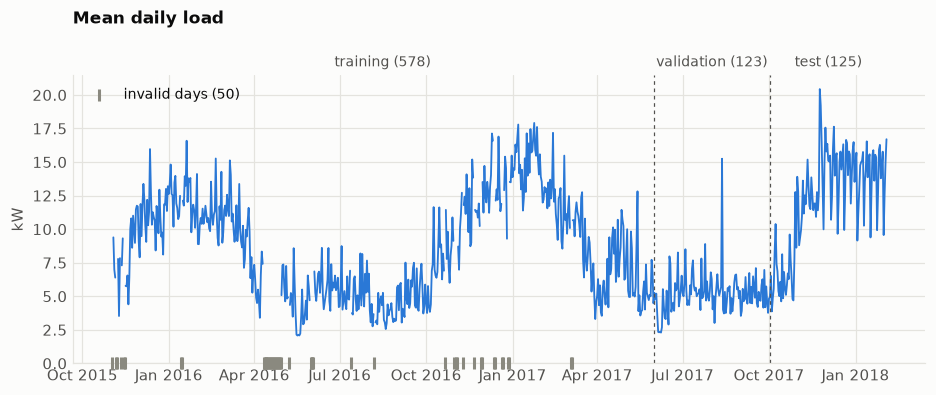

            hours  valid_hours
split                         
train       13871        12671
validation   2952         2952
test         3001         3001


In [2]:
daily = data["load_kw"].resample("D").mean()
daily_valid = data["valid_day"].resample("D").first().astype(bool)
split = data["split"].resample("D").first()

fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(daily.index, daily.where(daily_valid), color=COLORS["load"], linewidth=1.2)
invalid = daily[~daily_valid]
ax.scatter(invalid.index, np.zeros(len(invalid)), marker="|", s=60, color=COLORS["muted"],
           label=f"invalid days ({len(invalid)})", clip_on=False, zorder=3)
for name, label in [("train", "training"), ("validation", "validation"), ("test", "test")]:
    chunk = split[split == name]
    first, last = chunk.index[0], chunk.index[-1]
    if name != "train":
        ax.axvline(first, color=TEXT_SECONDARY, linewidth=0.8, linestyle=(0, (3, 3)))
    ax.annotate(f"{label} ({len(chunk)})", (first + (last - first) / 2, 1.02),
                xycoords=("data", "axes fraction"), ha="center", va="bottom", color=TEXT_SECONDARY, fontsize=9)
ax.set_ylim(0, None)
ax.set_ylabel("kW")
ax.set_title("Mean daily load", pad=34)
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", fontsize=9)
plt.show()

print(data.groupby("split", sort=False)["valid_day"].agg(hours="size", valid_hours="sum"))

**What we see**

- Out of 826 days, 50 are invalid. They are all in the training data; 19 fall in April 2016.
- Validation and test have no excluded days.
- The test set runs from 2 October 2017 to 3 February 2018: it covers autumn and winter only. There the mean load is 12.1 kW and PV 7.2 kW, against 8.7 kW and 11.7 kW in training. The final results will therefore describe the season least favourable to PV, not a whole year.
- Validation (June – 1 October 2017) is instead entirely summer.

## 2. Daily and weekly load profile

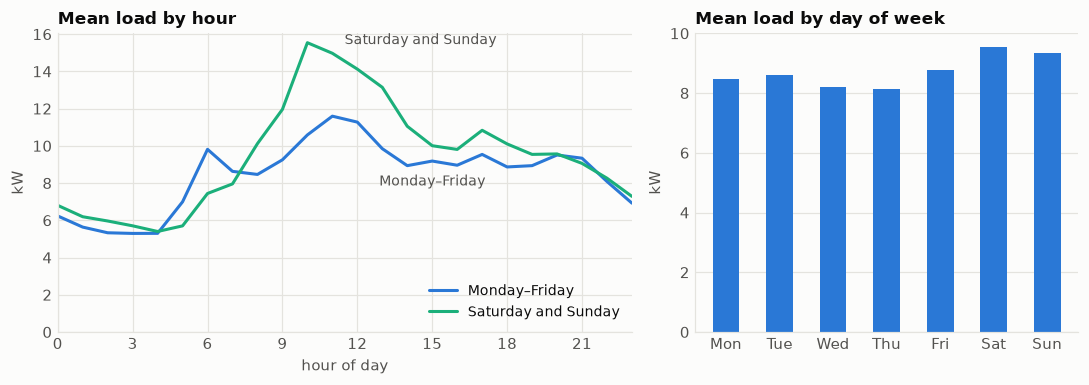

utc_timestamp         0    1    2    3    4    5    6    7     8     9     10    11    12    13    14    15   16    17    18   19   20   21   22   23
Monday–Friday        6.2  5.6  5.3  5.3  5.3  7.0  9.8  8.6   8.5   9.2  10.6  11.6  11.3   9.8   8.9   9.2  9.0   9.5   8.9  8.9  9.5  9.3  8.1  6.9
Saturday and Sunday  6.8  6.2  6.0  5.7  5.4  5.7  7.4  8.0  10.1  12.0  15.5  15.0  14.1  13.1  11.1  10.0  9.8  10.8  10.1  9.5  9.6  9.1  8.3  7.3

Mean by day of week: [8.48, 8.6, 8.19, 8.13, 8.78, 9.53, 9.35]


In [3]:
weekend = valid.index.day_of_week >= 5
profile = pd.DataFrame({
    "Monday–Friday": valid.loc[~weekend, "load_kw"].groupby(valid.index[~weekend].hour).mean(),
    "Saturday and Sunday": valid.loc[weekend, "load_kw"].groupby(valid.index[weekend].hour).mean(),
})
by_day = valid["load_kw"].groupby(valid.index.day_of_week).mean()

fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6), gridspec_kw={"width_ratios": [3, 2]})
for column, color in zip(profile.columns, [COLORS["load"], COLORS["alt"]]):
    left.plot(profile.index, profile[column], color=color, label=column)
left.annotate("Monday–Friday", (15, profile.iloc[15, 0]), xytext=(0, -16), textcoords="offset points",
              ha="center", color=TEXT_SECONDARY, fontsize=9)
left.annotate("Saturday and Sunday", (11, profile.iloc[11, 1]), xytext=(8, 6), textcoords="offset points",
              color=TEXT_SECONDARY, fontsize=9)
left.set_xticks(range(0, 24, 3))
left.set_xlim(0, 23)
left.set_ylim(0, None)
left.set_xlabel("hour of day")
left.set_ylabel("kW")
left.set_title("Mean load by hour")
left.legend(loc="lower right", fontsize=9)

right.bar(by_day.index, by_day.values, width=0.5, color=COLORS["load"])
right.set_xticks(range(7), ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"])
right.set_ylabel("kW")
right.set_title("Mean load by day of week")
right.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

print(profile.round(1).T.to_string())
print()
print("Mean by day of week:", by_day.round(2).tolist())

**What we see**

- At night the load drops to about 5 kW. On weekdays there is a first peak at 6 (about 10 kW) and a second between 10 and 12 (about 11.5 kW); in the evening it stays around 9 kW, with no sharp peak.
- At the weekend the morning starts later and the peak is higher: 15.5 kW at 10.
- Saturday and Sunday consume on average about 10% more than weekdays.
- The load comes from just two households, one of which has a heat pump and an electric car: the profile is less regular than that of a whole neighbourhood.

## 3. Seasonality of load and PV

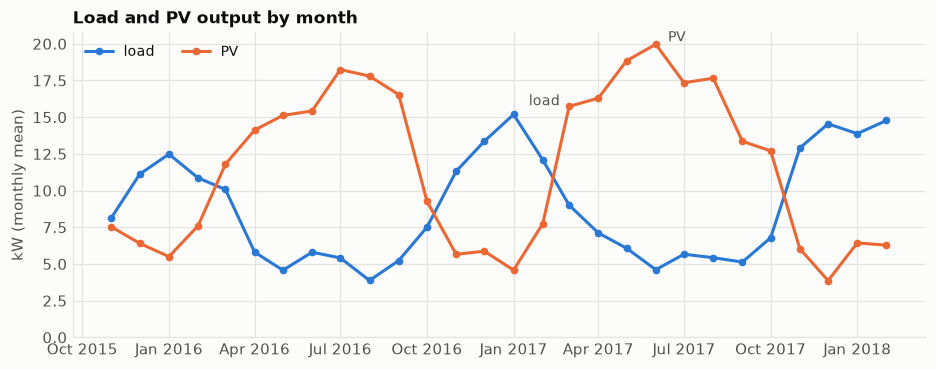

2016, valid days (324): load 62.4 MWh, PV 93.2 MWh
  hourly surplus 69.0 MWh, hourly deficit 38.2 MWh
  hours with PV > load: 32%
utc_timestamp  2015-11-01  2015-12-01  2016-01-01  2016-02-01  2016-03-01  2016-04-01  2016-05-01  2016-06-01  2016-07-01  2016-08-01  2016-09-01  2016-10-01  2016-11-01  2016-12-01  2017-01-01  2017-02-01  2017-03-01  2017-04-01  2017-05-01  2017-06-01  2017-07-01  2017-08-01  2017-09-01  2017-10-01  2017-11-01  2017-12-01  2018-01-01  2018-02-01
load_kw               8.2        11.1        12.5        10.9        10.1         5.8         4.6         5.8         5.4         3.9         5.2         7.5        11.3        13.4        15.2        12.1         9.0         7.1         6.1         4.6         5.7         5.4         5.1         6.8        12.9        14.5        13.9        14.8
pv_kw                 7.5         6.4         5.5         7.6        11.8        14.1        15.1        15.4        18.2        17.8        16.5         9.3         5.7 

In [4]:
monthly = valid[["load_kw", "pv_kw"]].groupby(valid.index.tz_localize(None).to_period("M")).mean()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(monthly.index, monthly["load_kw"], color=COLORS["load"], marker="o", markersize=4, label="load")
ax.plot(monthly.index, monthly["pv_kw"], color=COLORS["pv"], marker="o", markersize=4, label="PV")
ax.annotate("load", (monthly.index[14], monthly["load_kw"].iloc[14]), xytext=(10, 6), textcoords="offset points",
            color=TEXT_SECONDARY, fontsize=9)
ax.annotate("PV", (monthly.index[19], monthly["pv_kw"].iloc[19]), xytext=(8, 2), textcoords="offset points",
            color=TEXT_SECONDARY, fontsize=9)
ax.set_ylim(0, None)
ax.set_ylabel("kW (monthly mean)")
ax.set_title("Load and PV output by month")
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", ncols=2, fontsize=9)
plt.show()

year = valid.loc["2016"]
surplus = (year["pv_kw"] - year["load_kw"]).clip(lower=0).sum() / 1000
deficit = (year["load_kw"] - year["pv_kw"]).clip(lower=0).sum() / 1000
print(f"2016, valid days ({year.index.normalize().nunique()}): load {year['load_kw'].sum() / 1000:.1f} MWh, "
      f"PV {year['pv_kw'].sum() / 1000:.1f} MWh")
print(f"  hourly surplus {surplus:.1f} MWh, hourly deficit {deficit:.1f} MWh")
print(f"  hours with PV > load: {(year['pv_kw'] > year['load_kw']).mean():.0%}")
print(monthly.round(1).T.to_string())

**What we see**

- Load and PV have opposite seasonality. Load goes from 4–6 kW in summer to 11–15 kW in winter; PV from 15–20 kW in summer to 4–6 kW in winter.
- On the valid days of 2016, PV produces more than is consumed (93 MWh against 62 MWh), but not in the same hours: 69 MWh of surplus and 38 MWh of deficit remain.
- PV exceeds the load in only 32% of the hours.
- In summer the battery has plenty of surplus to move from day to night. In winter there is little surplus: there its value depends mostly on price differences.

## 4. Load and temperature

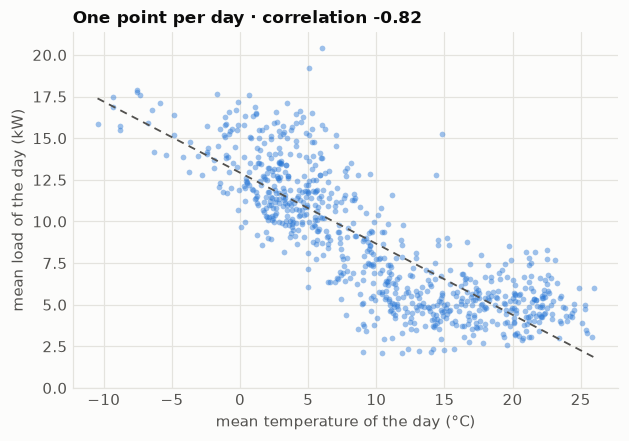

Daily correlation:  -0.819   slope: -0.43 kW per °C
Hourly correlation: -0.461
Mean load below 5 °C: 12.8 kW   above 15 °C: 5.1 kW


In [5]:
per_day = valid[["load_kw", "temperature_c"]].resample("D").mean().dropna()
slope, intercept = np.polyfit(per_day["temperature_c"], per_day["load_kw"], 1)
correlation = per_day["load_kw"].corr(per_day["temperature_c"])

fig, ax = plt.subplots(figsize=(6.4, 4.2))
ax.scatter(per_day["temperature_c"], per_day["load_kw"], s=14, color=COLORS["load"], alpha=0.45, linewidths=0)
temperatures = np.array([per_day["temperature_c"].min(), per_day["temperature_c"].max()])
ax.plot(temperatures, intercept + slope * temperatures, color=TEXT_SECONDARY, linewidth=1.2, linestyle=(0, (4, 3)))
ax.set_ylim(0, None)
ax.set_xlabel("mean temperature of the day (°C)")
ax.set_ylabel("mean load of the day (kW)")
ax.set_title(f"One point per day · correlation {correlation:.2f}")
plt.show()

print(f"Daily correlation:  {correlation:.3f}   slope: {slope:.2f} kW per °C")
print(f"Hourly correlation: {valid['load_kw'].corr(valid['temperature_c']):.3f}")
cold = per_day[per_day["temperature_c"] < 5]["load_kw"]
warm = per_day[per_day["temperature_c"] > 15]["load_kw"]
print(f"Mean load below 5 °C: {cold.mean():.1f} kW   above 15 °C: {warm.mean():.1f} kW")

**What we see**

- The correlation between mean load and mean temperature of the day is −0.82: each degree less adds about 0.43 kW.
- Below 5 °C the mean load is 12.8 kW, above 15 °C it is 5.1 kW.
- The relationship is not a straight line: above 12–15 °C the load stops falling. A tree model captures this without any transformation.
- Hour by hour the correlation is weaker (−0.46): temperature explains the level of the day, not the shape within it.

## 5. Price and carbon intensity over the 24 hours

The line is the mean by hour of day, the band runs from the 10th to the 90th percentile. These are two quantities with different units, hence two separate charts.

Day-ahead price: lowest mean at 3 (21), highest mean at 18 (41)
Grid carbon intensity: lowest mean at 13 (377), highest mean at 20 (443)


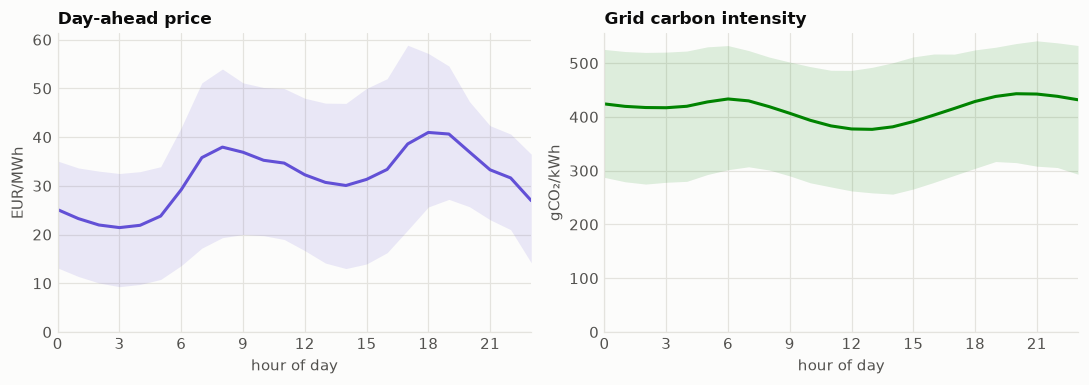

Hourly correlation between price and carbon intensity: 0.62
Hours with a negative price: 316
Difference between highest and lowest price within a day: median 23 EUR/MWh


In [6]:
def hourly_band(series):
    grouped = series.groupby(series.index.hour)
    return grouped.mean(), grouped.quantile(0.10), grouped.quantile(0.90)

panels = [
    ("price_eur_kwh", 1000, "price", "Day-ahead price", "EUR/MWh"),
    ("carbon_kg_kwh", 1000, "carbon", "Grid carbon intensity", "gCO₂/kWh"),
]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for ax, (column, factor, color, title, unit) in zip(axes, panels):
    mean, low, high = hourly_band(data[column] * factor)
    ax.fill_between(mean.index, low, high, color=COLORS[color], alpha=0.12, linewidth=0)
    ax.plot(mean.index, mean, color=COLORS[color])
    ax.set_xticks(range(0, 24, 3))
    ax.set_xlim(0, 23)
    ax.set_ylim(0, None)
    ax.set_xlabel("hour of day")
    ax.set_ylabel(unit)
    ax.set_title(title)
    print(f"{title}: lowest mean at {mean.idxmin()} ({mean.min():.0f}), highest mean at {mean.idxmax()} ({mean.max():.0f})")
fig.tight_layout()
plt.show()

print(f"Hourly correlation between price and carbon intensity: {data['price_eur_kwh'].corr(data['carbon_kg_kwh']):.2f}")
print(f"Hours with a negative price: {(data['price_eur_kwh'] < 0).sum()}")
daily_spread = (data["price_eur_kwh"] * 1000).resample("D").agg(lambda x: x.max() - x.min())
print(f"Difference between highest and lowest price within a day: median {daily_spread.median():.0f} EUR/MWh")

**What we see**

- The price has two peaks, at 8 (38 EUR/MWh) and at 18 (41 EUR/MWh), and its minimum at 3 in the morning (21 EUR/MWh). Within a day the difference between highest and lowest is 23 EUR/MWh in the median.
- Carbon intensity is lowest at 13 (377 gCO₂/kWh), when German solar is producing, and highest at 20 (443 gCO₂/kWh).
- The band of the carbon intensity is much wider than the variation of its mean: the day (wind, season) matters more than the hour.
- Price and carbon intensity are correlated (0.62) but not the same thing: the cheapest hours are at night, the cleanest at midday. Minimising cost and minimising emissions lead to different plans.
- There are 316 hours with a negative price.

## Consequences for the next phases

- **Load forecast.** It needs temperature, hour and the weekday/weekend distinction. The load of two households is irregular: the naive forecast will be hard to beat by much.
- **Invalid days.** They must be left out of the training targets and not used as lagged values.
- **23- and 25-hour days.** The two clock changes a year produce shorter or longer local days: the optimiser cannot assume a fixed 24 hours.
- **Evaluation.** The test set is autumn–winter only. That has to be said next to every result.
- **Cost and emissions.** The two objectives partly conflict: the Pareto front is worth computing.